In [1]:
import pandas as pd
df = pd.read_csv("D:\\Data science\\codes\\files\\sales.csv")
df

# EDA

# DATA CLEANING
print(df.isnull().sum())

# Data transformation
df.info()


Unnamed: 0     0
CompPrice      0
Income         0
Advertising    0
Population     0
Price          0
ShelveLoc      0
Age            0
Education      0
Urban          0
US             0
high           0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Unnamed: 0   400 non-null    int64 
 1   CompPrice    400 non-null    int64 
 2   Income       400 non-null    int64 
 3   Advertising  400 non-null    int64 
 4   Population   400 non-null    int64 
 5   Price        400 non-null    int64 
 6   ShelveLoc    400 non-null    object
 7   Age          400 non-null    int64 
 8   Education    400 non-null    int64 
 9   Urban        400 non-null    object
 10  US           400 non-null    object
 11  high         400 non-null    object
dtypes: int64(8), object(4)
memory usage: 37.6+ KB


In [5]:
df.head()

,Unnamed: 0,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,high
0,1,138,73,11,276,120,Bad,42,17,Yes,Yes,yes
1,2,111,48,16,260,83,Good,65,10,Yes,Yes,yes
2,3,113,35,10,269,80,Medium,59,12,Yes,Yes,yes
3,4,117,100,4,466,97,Medium,55,14,Yes,Yes,no
4,5,141,64,3,340,128,Bad,38,13,Yes,No,no


In [6]:
#---------------------------------------------------------
x_cont= df[df.columns[[1,2,3,4,5,7]]]

from sklearn.preprocessing import StandardScaler
SS = StandardScaler()
SS_X = SS.fit_transform(x_cont)
SS_X = pd.DataFrame(SS_X)
SS_X.columns = list(df.columns[[1,2,3,4,5,7]])
SS_X



,CompPrice,Income,Advertising,Population,Price,Age
0,0.850455,0.155361,0.657177,0.075819,0.177823,-0.699782
1,-0.912484,-0.739060,1.409957,-0.032882,-1.386854,0.721723
2,-0.781896,-1.204159,0.506621,0.028262,-1.513719,0.350895
3,-0.520720,1.121336,-0.396715,1.366649,-0.794814,0.103677
4,1.046337,-0.166631,-0.547271,0.510625,0.516132,-0.947000
...,...,...,...,...,...,...
395,0.850455,1.407551,1.560513,-0.420131,0.516132,-1.256023
396,0.915749,-1.633482,-0.547271,-1.547909,0.177823,0.103677
397,2.417512,-1.526151,0.807733,0.700853,1.827078,-0.823391
398,-1.630719,0.370022,0.054953,0.130170,-0.879391,-0.205346


In [7]:
from sklearn.preprocessing import LabelEncoder
LE = LabelEncoder()
df["ShelveLoc"] = LE.fit_transform(df["ShelveLoc"])
df["Urban"]     = LE.fit_transform(df["Urban"])
df["US"]        = LE.fit_transform(df["US"])
df["high"]      = LE.fit_transform(df["high"])
df.head()

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Unnamed: 0   400 non-null    int64
 1   CompPrice    400 non-null    int64
 2   Income       400 non-null    int64
 3   Advertising  400 non-null    int64
 4   Population   400 non-null    int64
 5   Price        400 non-null    int64
 6   ShelveLoc    400 non-null    int32
 7   Age          400 non-null    int64
 8   Education    400 non-null    int64
 9   Urban        400 non-null    int32
 10  US           400 non-null    int32
 11  high         400 non-null    int32
dtypes: int32(4), int64(8)
memory usage: 31.4 KB


In [8]:
df_cat = df[df.columns[[6,8,9,10,11]]]
df_cat

,ShelveLoc,Education,Urban,US,high
0,0,17,1,1,1
1,1,10,1,1,1
2,2,12,1,1,1
3,2,14,1,1,0
4,0,13,1,0,0
...,...,...,...,...,...
395,1,14,1,1,1
396,2,11,0,1,0
397,2,18,1,1,0
398,0,12,1,1,0


In [9]:
df_new = pd.concat([SS_X,df_cat],axis=1)
df_new

,CompPrice,Income,Advertising,Population,Price,Age,ShelveLoc,Education,Urban,US,high
0,0.850455,0.155361,0.657177,0.075819,0.177823,-0.699782,0,17,1,1,1
1,-0.912484,-0.739060,1.409957,-0.032882,-1.386854,0.721723,1,10,1,1,1
2,-0.781896,-1.204159,0.506621,0.028262,-1.513719,0.350895,2,12,1,1,1
3,-0.520720,1.121336,-0.396715,1.366649,-0.794814,0.103677,2,14,1,1,0
4,1.046337,-0.166631,-0.547271,0.510625,0.516132,-0.947000,0,13,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
395,0.850455,1.407551,1.560513,-0.420131,0.516132,-1.256023,1,14,1,1,1
396,0.915749,-1.633482,-0.547271,-1.547909,0.177823,0.103677,2,11,0,1,0
397,2.417512,-1.526151,0.807733,0.700853,1.827078,-0.823391,2,18,1,1,0
398,-1.630719,0.370022,0.054953,0.130170,-0.879391,-0.205346,0,12,1,1,0


In [10]:
# data partition
Y = df_new["high"]
X = df_new.drop(df_new[['high']],axis=1)


In [11]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(X,Y, test_size = 0.3)

In [10]:
#---------------------------------------------------------1
from sklearn.tree import DecisionTreeClassifier   # decision tree regressor
model = DecisionTreeClassifier(criterion='gini') # entropy
model.fit(X_train,Y_train)

Y_pred_train = model.predict(X_train)
Y_pred_test = model.predict(X_test)

from sklearn.metrics import accuracy_score, log_loss
training_accuracy  = accuracy_score(Y_train,Y_pred_train)
test_accuracy  = accuracy_score(Y_test,Y_pred_test)
training_loss  = log_loss(Y_train,Y_pred_train)
test_loss  = log_loss(Y_test,Y_pred_test)

import numpy as np
print("trianing accuracy:", np.round(training_accuracy,2))
print("test accuracy:", np.round(test_accuracy,2))
print("trianing loss:", np.round(training_loss,2))
print("test loss:", np.round(test_loss,2))


trianing accuracy: 1.0
test accuracy: 0.66
trianing loss: 0.0
test loss: 12.31


In [ ]:
#=============================================================
# shuffle split
#=============================================================
training_accracy = []
test_accuracy = []
training_loss = []
test_loss = []

for i in range(1, 501):
    X_train,X_test,Y_train,Y_test = train_test_split(X,Y, test_size=0.30, random_state=i, stratify=Y)
    model = DecisionTreeClassifier(criterion='gini',max_depth=7) # 'entropy' generally maxDepth is null
    model.fit(X_train,Y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test  = model.predict(X_test)
    training_accracy.append(accuracy_score(Y_train,y_pred_train))
    test_accuracy.append(accuracy_score(Y_test,y_pred_test))
    training_loss.append(log_loss(Y_train,Y_pred_train))
    test_loss.append(log_loss(Y_test,Y_pred_test))

print("Cross validation: Training accuracy score:", np.round(np.mean(training_accracy),2))
print("Cross validation: Test accuracy score:", np.round(np.mean(test_accuracy),2))
print("Cross validation: trianing loss:", np.round(np.mean(training_loss),2))
print("Cross validation: test loss:", np.round(np.mean(test_loss),2))


Cross validation: Training accuracy score: 0.96
Cross validation: Test accuracy score: 0.72
Cross validation: trianing loss: 17.36
Cross validation: test loss: 17.58


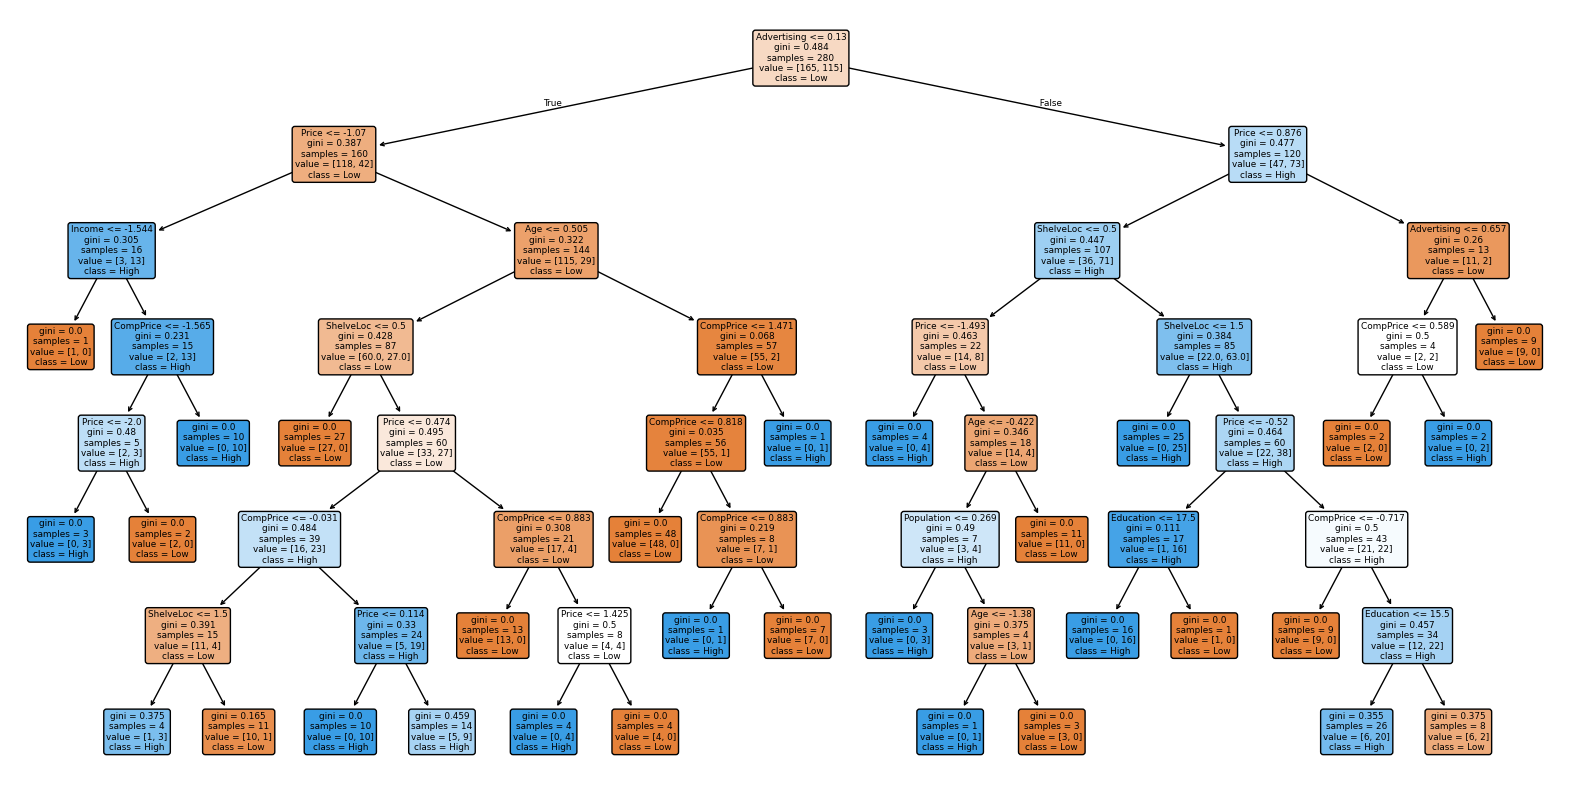

In [12]:
# prompt: visualize the decision tree from above model

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Assuming 'model' is your trained DecisionTreeClassifier
plt.figure(figsize=(20,10))
plot_tree(model, filled=True, feature_names=X.columns, class_names=['Low', 'High'], rounded=True) # Assuming 'high' represents two classes: Low and High
plt.show()


In [13]:
# prompt: count the total number of nodes and depth of the tree from above

from sklearn.tree import DecisionTreeClassifier
# ... (Your existing code) ...

# Assuming 'model' is your trained DecisionTreeClassifier
n_nodes = model.tree_.node_count
depth = model.tree_.max_depth

print(f"Number of nodes: {n_nodes}")
print(f"Depth of the tree: {depth}")


Number of nodes: 59
Depth of the tree: 7


In [28]:
# prompt: give me the code to write bagging classifier to the above data

from sklearn.ensemble import BaggingClassifier  # bagging regressor

# Bagging Classifier
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(criterion='gini'),
                                  n_estimators=100, random_state=42,
                                  max_samples=0.6,max_features=0.7)
bagging_model.fit(X_train, Y_train)

y_pred_train_bagging = bagging_model.predict(X_train)
y_pred_test_bagging = bagging_model.predict(X_test)

training_accuracy_bagging = accuracy_score(Y_train, y_pred_train_bagging)
test_accuracy_bagging = accuracy_score(Y_test, y_pred_test_bagging)
training_loss_bagging = log_loss(Y_train, y_pred_train_bagging)
test_loss_bagging = log_loss(Y_test, y_pred_test_bagging)

print("Bagging - Training Accuracy:", training_accuracy_bagging)
print("Bagging - Test Accuracy:", test_accuracy_bagging)
print("Bagging - Training Loss:", training_loss_bagging)
print("Bagging - Test Loss:", test_loss_bagging)


Bagging - Training Accuracy: 1.0
Bagging - Test Accuracy: 0.8083333333333333
Bagging - Training Loss: 2.220446049250313e-16
Bagging - Test Loss: 6.908366899580787


In [15]:
from sklearn.ensemble import BaggingClassifier  # bagging regressor
from sklearn.linear_model import LogisticRegression

# Bagging Classifier
bagging_log_model = BaggingClassifier(estimator=LogisticRegression(),
                                  n_estimators=100, random_state=42,
                                  max_samples=0.6,max_features=0.7)
bagging_log_model.fit(X_train, Y_train)

y_pred_train_bagging = bagging_log_model.predict(X_train)
y_pred_test_bagging = bagging_log_model.predict(X_test)

training_accuracy_bagging = accuracy_score(Y_train, y_pred_train_bagging)
test_accuracy_bagging = accuracy_score(Y_test, y_pred_test_bagging)
training_loss_bagging = log_loss(Y_train, y_pred_train_bagging)
test_loss_bagging = log_loss(Y_test, y_pred_test_bagging)

print("Bagging -logistic- Training Accuracy:", training_accuracy_bagging)
print("Bagging -logistic- Test Accuracy:", test_accuracy_bagging)
print("Bagging -logistic- Training Loss:", training_loss_bagging)
print("Bagging -logistic- Test Loss:", test_loss_bagging)


Bagging -logistic- Training Accuracy: 0.8214285714285714
Bagging -logistic- Test Accuracy: 0.7583333333333333
Bagging -logistic- Training Loss: 6.436366676628063
Bagging -logistic- Test Loss: 8.710549569036646


In [29]:
from sklearn.model_selection import GridSearchCV
# prompt: use grid search cv to the above bagging classifier as decision tree estimator and give the different parameters for max_features, max_samples, n_estimators



# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.6, 0.7, 0.8],
    'max_features': [0.6, 0.7, 0.8]
}

# Create the bagging classifier with a decision tree estimator
bagging_model = BaggingClassifier(estimator=DecisionTreeClassifier(criterion='gini'), random_state=42)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=bagging_model, param_grid=param_grid, cv=100, scoring='accuracy')
# Fit the grid search to the data
grid_search.fit(X_train, Y_train)


# Print the best parameters and the best score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred_test)
print("Test accuracy:", test_accuracy)


Best parameters: {'max_features': 0.7, 'max_samples': 0.6, 'n_estimators': 200}
Best score: 0.83
Test accuracy: 0.825


In [32]:
df.shape

(400, 12)

In [33]:
X_train.shape

(280, 10)

In [42]:
# prompt: just like above as you run the code for bagging classifier i need a code using random forests

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss

# Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=300, random_state=42,
                                  max_samples = 0.6, max_features=0.7)
rf_model.fit(X_train, Y_train) #  224 samples (0.8 * 280)

y_pred_train_rf = rf_model.predict(X_train) # 280 samples (224+56)
y_pred_test_rf = rf_model.predict(X_test) # 120

training_accuracy_rf = accuracy_score(Y_train, y_pred_train_rf)
test_accuracy_rf = accuracy_score(Y_test, y_pred_test_rf)
training_loss_rf = log_loss(Y_train, y_pred_train_rf)
test_loss_rf = log_loss(Y_test, y_pred_test_rf)

print("Random Forest - Training Accuracy:", training_accuracy_rf)
print("Random Forest - Test Accuracy:", test_accuracy_rf)
print("Random Forest - Training Loss:", training_loss_rf)
print("Random Forest - Test Loss:", test_loss_rf)


Random Forest - Training Accuracy: 1.0
Random Forest - Test Accuracy: 0.8
Random Forest - Training Loss: 2.220446049250313e-16
Random Forest - Test Loss: 7.20873067782343


In [ ]:
y_pred_train_rf.shape

In [ ]:
y_pred_test_rf.shape

In [43]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.6, 0.7, 0.8],
    'max_features': [0.6, 0.7, 0.8]
}

# Create the bagging classifier with a decision tree estimator
rf_model = RandomForestClassifier(n_estimators=100, random_state=42,
                                  max_samples=0.6, max_features=0.7)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=rf_model, param_grid=param_grid, cv=10, scoring='accuracy')

# Fit the grid search to the data
grid_search.fit(X_train, Y_train)

# Print the best parameters and the best score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred_test)
print("Test accuracy:", test_accuracy)


Best parameters: {'max_features': 0.8, 'max_samples': 0.6, 'n_estimators': 200}
Best score: 0.7964285714285715
Test accuracy: 0.7833333333333333


In [18]:
# prompt: give me the code for gradient boosting classifier as above

from sklearn.ensemble import GradientBoostingClassifier # gradientboosting regressor

# Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42, learning_rate=0.1,max_features=0.7)
gb_model.fit(X_train, Y_train)

y_pred_train_gb = gb_model.predict(X_train)
y_pred_test_gb = gb_model.predict(X_test)

from sklearn.metrics import accuracy_score, log_loss
training_accuracy_gb = accuracy_score(Y_train, y_pred_train_gb)
test_accuracy_gb = accuracy_score(Y_test, y_pred_test_gb)
training_loss_gb = log_loss(Y_train, y_pred_train_gb)
test_loss_gb = log_loss(Y_test, y_pred_test_gb)

print("Gradient Boosting - Training Accuracy:", training_accuracy_gb)
print("Gradient Boosting - Test Accuracy:", test_accuracy_gb)
print("Gradient Boosting - Training Loss:", training_loss_gb)
print("Gradient Boosting - Test Loss:", test_loss_gb)


Gradient Boosting - Training Accuracy: 0.9964285714285714
Gradient Boosting - Test Accuracy: 0.825
Gradient Boosting - Training Loss: 0.12872733353256147
Gradient Boosting - Test Loss: 6.307639343095502


In [15]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 150 ,200,250],
    'max_features': [0.6, 0.7, 0.8],
    'learning_rate': [0.1, 0.5, 1, 1.5,2]
}

# Create the bagging classifier with a decision tree estimator
gb_model = GradientBoostingClassifier(random_state=42)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=gb_model, param_grid=param_grid, cv=10, scoring='accuracy')

# Fit the grid search to the data
grid_search.fit(X_train, Y_train)

# Print the best parameters and the best score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred_test)
print("Test accuracy:", test_accuracy)


Best parameters: {'learning_rate': 0.1, 'max_features': 0.6, 'n_estimators': 200}
Best score: 0.8428571428571429
Test accuracy: 0.8


In [19]:
# prompt: fit the model using adaboost classifier as above with decision tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost Classifier
ab_model = AdaBoostClassifier(n_estimators=100, random_state=42, learning_rate=0.1,estimator=DecisionTreeClassifier(criterion='gini'))
ab_model.fit(X_train, Y_train)

y_pred_train_ab = ab_model.predict(X_train)
y_pred_test_ab = ab_model.predict(X_test)

training_accuracy_ab = accuracy_score(Y_train, y_pred_train_ab)
test_accuracy_ab = accuracy_score(Y_test, y_pred_test_ab)
training_loss_ab = log_loss(Y_train, y_pred_train_ab)
test_loss_ab = log_loss(Y_test, y_pred_test_ab)

print("AdaBoost - Training Accuracy:", training_accuracy_ab)
print("AdaBoost - Test Accuracy:", test_accuracy_ab)
print("AdaBoost - Training Loss:", training_loss_ab)
print("AdaBoost - Test Loss:", test_loss_ab)


AdaBoost - Training Accuracy: 1.0
AdaBoost - Test Accuracy: 0.7416666666666667
AdaBoost - Training Loss: 2.220446049250313e-16
AdaBoost - Test Loss: 9.311277125521933


In [20]:
# prompt: fit the model using adaboost classifier as above with logistic regression

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost Classifier
ab_model = AdaBoostClassifier(n_estimators=100, random_state=42, learning_rate=0.1,estimator=LogisticRegression(max_iter=1000))
ab_model.fit(X_train, Y_train)

y_pred_train_ab = ab_model.predict(X_train)
y_pred_test_ab = ab_model.predict(X_test)

training_accuracy_ab = accuracy_score(Y_train, y_pred_train_ab)
test_accuracy_ab = accuracy_score(Y_test, y_pred_test_ab)
training_loss_ab = log_loss(Y_train, y_pred_train_ab)
test_loss_ab = log_loss(Y_test, y_pred_test_ab)

print("AdaBoost - Training Accuracy:", training_accuracy_ab)
print("AdaBoost - Test Accuracy:", test_accuracy_ab)
print("AdaBoost - Training Loss:", training_loss_ab)
print("AdaBoost - Test Loss:", test_loss_ab)


AdaBoost - Training Accuracy: 0.8107142857142857
AdaBoost - Test Accuracy: 0.8416666666666667
AdaBoost - Training Loss: 6.822548677225746
AdaBoost - Test Loss: 5.706911786610216


In [21]:
# prompt: fit the model using adaboost classifier as above with SVC classifer

from sklearn.svm import SVC
from sklearn.ensemble import AdaBoostClassifier

# AdaBoost Classifier
ab_model = AdaBoostClassifier(n_estimators=200, random_state=42, learning_rate=0.1,estimator=SVC(kernel='linear',C = 4))
ab_model.fit(X_train, Y_train)

y_pred_train_ab = ab_model.predict(X_train)
y_pred_test_ab = ab_model.predict(X_test)

training_accuracy_ab = accuracy_score(Y_train, y_pred_train_ab)
test_accuracy_ab = accuracy_score(Y_test, y_pred_test_ab)
training_loss_ab = log_loss(Y_train, y_pred_train_ab)
test_loss_ab = log_loss(Y_test, y_pred_test_ab)

print("AdaBoost - Training Accuracy:", training_accuracy_ab)
print("AdaBoost - Test Accuracy:", test_accuracy_ab)
print("AdaBoost - Training Loss:", training_loss_ab)
print("AdaBoost - Test Loss:", test_loss_ab)


AdaBoost - Training Accuracy: 0.8142857142857143
AdaBoost - Test Accuracy: 0.85
AdaBoost - Training Loss: 6.693821343693186
AdaBoost - Test Loss: 5.406548008367573


In [24]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier


# Define the parameter grid
param_grid = {
    'n_estimators': [100, 150, 300, 400],
    'learning_rate': [0.01,0.1, 0.5, 1, 1.5,2]
}

# Create the bagging classifier with a decision tree estimator
ab_model = AdaBoostClassifier(estimator=DecisionTreeClassifier())

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=ab_model, param_grid=param_grid, cv=100, scoring='accuracy')

# Fit the grid search to the data
grid_search.fit(X_train, Y_train)

# Print the best parameters and the best score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred_test)
print("Test accuracy:", test_accuracy)


Best parameters: {'learning_rate': 1, 'n_estimators': 300}
Best score: 0.7583333333333334
Test accuracy: 0.75


In [28]:
%pip install xgboost

   ---------------------------------------- 56.8/56.8 MB 4.3 MB/s  0:00:13

  Using cached xgboost-3.0.4-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 56.8/56.8 MB 2.9 MB/s  0:00:19


In [29]:
# prompt: write down the code using XGBoost as above used models

# Import necessary libraries
import xgboost as xgb


# XGBoost Classifier
xgb_model = xgb.XGBClassifier(n_estimators = 100,Learning_rate=0.1,gamma=100,reg_lambda = 10)
xgb_model.fit(X_train, Y_train)

y_pred_train_xgb = xgb_model.predict(X_train)
y_pred_test_xgb = xgb_model.predict(X_test)

training_accuracy_xgb = accuracy_score(Y_train, y_pred_train_xgb)
test_accuracy_xgb = accuracy_score(Y_test, y_pred_test_xgb)
training_loss_xgb = log_loss(Y_train, y_pred_train_xgb)
test_loss_xgb = log_loss(Y_test, y_pred_test_xgb)

print("XGBoost - Training Accuracy:", training_accuracy_xgb)
print("XGBoost - Test Accuracy:", test_accuracy_xgb)
print("XGBoost - Training Loss:", training_loss_xgb)
print("XGBoost - Test Loss:", test_loss_xgb)


XGBoost - Training Accuracy: 0.5928571428571429
XGBoost - Test Accuracy: 0.5833333333333334
XGBoost - Training Loss: 14.674916022711983
XGBoost - Test Loss: 15.018188912132144


c:\Users\abhir\AppData\Local\Programs\Python\Python310\lib\site-packages\xgboost\training.py:183: UserWarning: [08:57:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "Learning_rate" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [30]:
# prompt: using grid search cv , i want to run all these combinations accordingly n_estimators = 100,200,300
# Learning_rate=0.1,1,10
# gamma=50,100,200,
# reg_lambda = 10,50,100

from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.1, 1, 0.01],
    'gamma': [10, 20, 50],
    'reg_lambda': [1, 5, 10]
}

# Create the XGBoost classifier
xgb_model = xgb.XGBClassifier()

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, cv=5, scoring='accuracy') # You can change scoring as needed

# Fit the grid search to the data
grid_search.fit(X_train, Y_train)

# Get the best parameters and best score
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"Best parameters: {best_params}")
print(f"Best score: {best_score}")

# Evaluate the best model on the test set
best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)
test_accuracy = accuracy_score(Y_test, y_pred_test)
print(f"Test accuracy of the best model: {test_accuracy}")


Best parameters: {'gamma': 10, 'learning_rate': 1, 'n_estimators': 100, 'reg_lambda': 1}
Best score: 0.7392857142857143
Test accuracy of the best model: 0.7916666666666666
